In [1]:
import polars as pl
import numpy as np
import polars.selectors as sl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sentence_transformers import SentenceTransformer, util 
from itertools import combinations
import re

pl.Config.set_fmt_str_lengths(500)
pl.Config.set_tbl_rows(-1)

polars.config.Config

In [2]:
#file_path = Path('../outputs/LLM/glint/risultati_llm_20261115_193713.csv')
# file_path = Path('../outputs/LLM/glint/risultati_llm_20261114_162646.csv')
file_path = Path('../outputs/LLM/feret/risultati_llm_20261123_005054.csv')
df = pl.read_csv(
    file_path,
    separator=',',
    infer_schema_length=None
).drop(
    ['timestamp']
)

df.head(5)

modello,file,prompt,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
str,str,str,str,i64,f64,i64,i64
"""LFM2-1.2B""","""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The face photo features a head turned sharply, eyes slightly open, mouth closed, with a neutral expression. The subject's gaze is directed away from the camera.""",26,0.16,92,33
"""LFM2-1.2B""","""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.""",21,0.1,95,27
"""LFM2-1.2B""","""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.""",21,0.09,95,27
"""LFM2-1.2B""","""00552_940519_ql.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head slightly turned. Good aspects: face unobstructed; neutral expression; mouth closed.""","""The photo features a face with a slight tilt of the head, a neutral expression, and a closed mouth, all unobstructed.""",21,0.1,93,29
"""LFM2-1.2B""","""00505_940519_ql.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head slightly turned; face partly covered (for example by glasses). Good aspects: neutral expression; mouth closed.""","""The face photo shows a neutral expression with a slightly turned head and a partially covered mouth, likely due to glasses. The overall appearance is clean and unobtrusive.""",28,0.12,96,35


In [3]:
models = {k[0]: v for k, v in df.partition_by('modello', as_dict=True).items()}

In [4]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','risposta', 'tempo_s', 'num_parole'].head(5))

--- LFM2-1.2B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The face photo features a head turned sharply, eyes slightly open, mouth closed, with a neutral expression. The subject's gaze is directed away from the camera.""",0.16,26
"""00170_931230_pl.png""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.""",0.1,21
"""00445_940422_pl.png""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.""",0.09,21
"""00552_940519_ql.png""","""The photo features a face with a slight tilt of the head, a neutral expression, and a closed mouth, all unobstructed.""",0.1,21
"""00505_940519_ql.png""","""The face photo shows a neutral expression with a slightly turned head and a partially covered mouth, likely due to glasses. The overall appearance is clean and unobtrusive.""",0.12,28


--- Gemma-3-1B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The image features a head turned slightly to the side, presenting a neutral expression. The mouth is closed, creating a calm and composed appearance.""",0.22,24
"""00170_931230_pl.png""","""The image features a person with a significantly turned head, presenting a lack of direct engagement with the camera. The expression is not neutral, and the mouth is open, creating a slightly inquisitive pose.""",0.21,34
"""00445_940422_pl.png""","""The image features a person with a significantly turned head, presenting a slightly open mouth. The facial expression is not neutral, and the head is angled away from the camera.""",0.17,30
"""00552_940519_ql.png""","""The photograph depicts a face turned slightly to the left, with a neutral expression. The face is largely unobstructed, showcasing a closed mouth.""",0.15,23
"""00505_940519_ql.png""","""Here’s a description: A face is turned slightly to the left, with a portion of the face obscured by glasses. The expression is neutral, with the mouth closed, creating a calm and composed appearance.""",0.22,34


--- Qwen3-4B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The photo shows a neutral expression with a closed mouth. The head is strongly turned, not facing the camera.""",0.29,19
"""00170_931230_pl.png""","""The photo shows a face with the head strongly turned, non-neutral expression, and mouth open. No issues were found.""",0.24,19
"""00445_940422_pl.png""","""The photo shows a head strongly turned, non-neutral expression, and mouth open. No issues were found.""",0.22,16
"""00552_940519_ql.png""","""The face is unobstructed, with a neutral expression and closed mouth. The head is slightly turned, which is noted as an issue.""",0.29,22
"""00505_940519_ql.png""","""The face is neutral with a closed mouth. Part of the face is covered, and the head is slightly turned. No problems were found.""",0.27,24


... (4 outputs left out)

--- Qwen3-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The passport-style face photo shows a head that is strongly turned, not facing the camera. The subject has a neutral expression with the mouth closed.""",0.5,25
"""00170_931230_pl.png""","""The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted.""",0.53,29
"""00445_940422_pl.png""","""The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted.""",0.51,29
"""00552_940519_ql.png""","""The passport-style face photo shows a head slightly turned. The face is unobstructed with a neutral expression and the mouth closed.""",0.42,21
"""00505_940519_ql.png""","""The passport-style face photo shows a head slightly turned. The face is partly covered, for example by glasses. The expression is neutral, and the mouth is closed. No problems were found.""",0.58,31


--- Llama-3.1-8B ---


file,risposta,tempo_s,num_parole
str,str,f64,i64
"""00266_940128_pl.png""","""The passport-style face photo shows a person with a neutral expression and mouth closed, but the head is not facing the camera directly. No problems were found.""",0.54,27
"""00170_931230_pl.png""","""The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found.""",0.49,28
"""00445_940422_pl.png""","""The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found.""",0.48,28
"""00552_940519_ql.png""","""The passport-style face photo shows a neutral expression with the mouth closed, and the face is unobstructed. The head is slightly turned, but no problems were found.""",0.52,27
"""00505_940519_ql.png""","""The passport-style face photo shows a neutral expression with the mouth closed. The photo has some issues, including the head being slightly turned and the face being partly covered.""",0.49,29


In [5]:
target = ['num_parole', 'tempo_s', 'prompt_tokens', 'completion_tokens']

for model, df_sub in models.items():
    print(f"=== Statistiche per il modello: {model} ===")
    
    display(df_sub[target].describe())
    print("\n")

=== Statistiche per il modello: LFM2-1.2B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",25.372895,0.111772,93.785485,32.968925
"""std""",4.502621,0.015567,1.774339,5.315326
"""min""",18.0,0.08,81.0,24.0
"""25%""",21.0,0.1,92.0,29.0
"""50%""",26.0,0.11,93.0,33.0
"""75%""",28.0,0.12,95.0,36.0
"""max""",34.0,0.16,99.0,43.0




=== Statistiche per il modello: Gemma-3-1B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",27.36648,0.183494,94.102646,35.036488
"""std""",3.679186,0.025047,2.505476,5.300918
"""min""",22.0,0.15,82.0,28.0
"""25%""",24.0,0.16,93.0,29.0
"""50%""",26.0,0.18,93.0,34.0
"""75%""",30.0,0.21,95.0,40.0
"""max""",34.0,0.24,101.0,46.0




=== Statistiche per il modello: Qwen3-4B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",20.324779,0.240355,94.785485,25.496191
"""std""",3.583372,0.039447,1.774339,4.361335
"""min""",10.0,0.13,82.0,13.0
"""25%""",17.0,0.21,93.0,23.0
"""50%""",19.0,0.23,94.0,24.0
"""75%""",23.0,0.27,96.0,28.0
"""max""",31.0,0.38,100.0,40.0


... (4 outputs left out)



=== Statistiche per il modello: Qwen3-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",23.964715,0.455086,94.785485,30.571371
"""std""",3.168859,0.047851,1.774339,3.333047
"""min""",18.0,0.36,82.0,25.0
"""25%""",22.0,0.43,93.0,29.0
"""50%""",24.0,0.45,94.0,30.0
"""75%""",25.0,0.47,96.0,31.0
"""max""",31.0,0.59,100.0,39.0




=== Statistiche per il modello: Llama-3.1-8B ===


statistic,num_parole,tempo_s,prompt_tokens,completion_tokens
str,f64,f64,f64,f64
"""count""",4988.0,4988.0,4988.0,4988.0
"""null_count""",0.0,0.0,0.0,0.0
"""mean""",28.231155,0.51004,116.785485,35.440056
"""std""",1.333687,0.038637,1.774339,2.647421
"""min""",25.0,0.45,104.0,31.0
"""25%""",27.0,0.48,115.0,33.0
"""50%""",28.0,0.51,116.0,36.0
"""75%""",29.0,0.54,118.0,37.0
"""max""",33.0,0.61,122.0,41.0


In [6]:
for model, m_df in models.items():
    print(f"--- {model} ---")
    display(m_df['file','prompt','risposta'].head(3))

--- LFM2-1.2B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The face photo features a head turned sharply, eyes slightly open, mouth closed, with a neutral expression. The subject's gaze is directed away from the camera."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes."""


--- Gemma-3-1B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The image features a head turned slightly to the side, presenting a neutral expression. The mouth is closed, creating a calm and composed appearance."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The image features a person with a significantly turned head, presenting a lack of direct engagement with the camera. The expression is not neutral, and the mouth is open, creating a slightly inquisitive pose."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The image features a person with a significantly turned head, presenting a slightly open mouth. The facial expression is not neutral, and the head is angled away from the camera."""


--- Qwen3-4B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The photo shows a neutral expression with a closed mouth. The head is strongly turned, not facing the camera."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The photo shows a face with the head strongly turned, non-neutral expression, and mouth open. No issues were found."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The photo shows a head strongly turned, non-neutral expression, and mouth open. No issues were found."""


... (4 outputs left out)

--- Qwen3-8B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The passport-style face photo shows a head that is strongly turned, not facing the camera. The subject has a neutral expression with the mouth closed."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted."""


--- Llama-3.1-8B ---


file,prompt,risposta
str,str,str
"""00266_940128_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera). Good aspects: neutral expression; mouth closed.""","""The passport-style face photo shows a person with a neutral expression and mouth closed, but the head is not facing the camera directly. No problems were found."""
"""00170_931230_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found."""
"""00445_940422_pl.png""","""Describe a passport-style face photo in at most 2 sentences (max 45 words), using ONLY the facts below. Do not mention numbers, and do not infer identity, age, gender, emotion or any detail that is not listed. If Issues is none, say that no problems were found. Issues: head strongly turned (not facing the camera); non-neutral expression; mouth open. Good aspects: none.""","""The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found."""


### Confronto fra modelli: similarità fra le risposte

In [7]:
embedder_name = 'paraphrase-multilingual-MiniLM-L12-v2'
emb_model = SentenceTransformer(embedder_name)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

In [8]:
embeddings = {
    nome: emb_model.encode(
        d["risposta"].to_list(),  
        normalize_embeddings=True,
        batch_size=64,
        show_progress_bar=True,
    )
    for nome, d in models.items()
}

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

Batches:   0%|          | 0/78 [00:00<?, ?it/s]

In [9]:
models_name = list(embeddings)

similarities = {
    (a,b): (embeddings[a] * embeddings[b]).sum(axis=1)
    for a,b in combinations(models_name,2)
}

M = np.eye(len(models_name))
for i,a in enumerate(models_name):
    for j,b in enumerate(models_name):
        if i < j:
            M[i, j] = M[j, i] = similarities[(a, b)].mean()

mat = pl.DataFrame(M,schema=models_name).with_columns(pl.Series('modello',models_name))

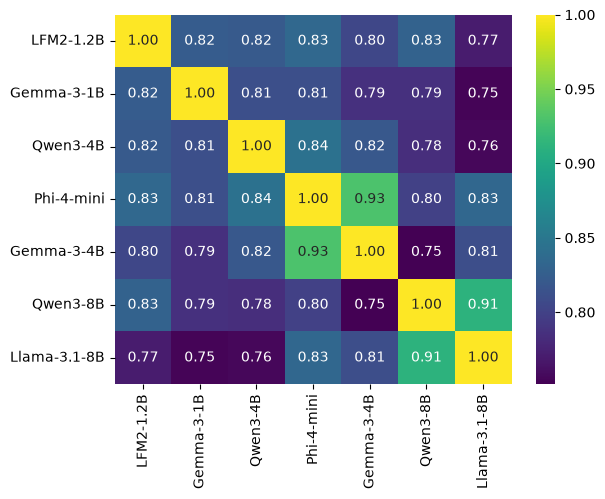

In [10]:
sns.heatmap(M, xticklabels=models_name, yticklabels=models_name, annot=True, fmt=".2f", cmap="viridis")
plt.show()

In [11]:
righe = []
for (a, b), s in similarities.items():
    righe.append({
        "A": a, "B": b,
        "media": s.mean(),
        "p5": np.percentile(s, 5),
        "mediana": np.median(s),
        "p95": np.percentile(s, 95),
    })
confronto = pl.DataFrame(righe).sort("media", descending=True)

In [12]:
confronto

A,B,media,p5,mediana,p95
str,str,f64,f64,f64,f64
"""Phi-4-mini""","""Gemma-3-4B""",0.929797,0.851259,0.925217,0.977386
"""Qwen3-8B""","""Llama-3.1-8B""",0.910894,0.85035,0.903858,0.963602
"""Qwen3-4B""","""Phi-4-mini""",0.844491,0.760385,0.850669,0.907409
"""LFM2-1.2B""","""Phi-4-mini""",0.83481,0.755543,0.860641,0.894627
"""Phi-4-mini""","""Llama-3.1-8B""",0.833516,0.742627,0.851334,0.880696
"""LFM2-1.2B""","""Qwen3-8B""",0.828526,0.742326,0.82919,0.925418
"""LFM2-1.2B""","""Gemma-3-1B""",0.822351,0.706459,0.826662,0.941212
"""LFM2-1.2B""","""Qwen3-4B""",0.820484,0.711265,0.807863,0.937493
"""Qwen3-4B""","""Gemma-3-4B""",0.818884,0.740326,0.79933,0.896074


In [13]:
def get_prompt_features(p: str):
    issues, good = [], []

    m_issues = re.search(r"Issues:\s*(.*?)(?:\n|$)", p)
    m_good = re.search(r"Good aspects:\s*(.*?)(?:\n|$)", p)

    if m_issues:
        issues = [x.strip() for x in m_issues.group(1).split(";") if x.strip()]
    if m_good:
        good = [x.strip() for x in m_good.group(1).split(";") if x.strip()]

    return issues, good

In [14]:
for nome, d in list(models.items()):
    liste = [get_prompt_features(p) for p in d["prompt"].to_list()]
    models[nome] = d.with_columns(
        pl.Series("issues", [l[0] for l in liste], dtype=pl.List(pl.String)),
        pl.Series("good",   [l[1] for l in liste], dtype=pl.List(pl.String)),
    )

from transformers import pipeline

nli = pipeline("text-classification",
               model="cross-encoder/nli-deberta-v3-small", device=-1)

def valuta_modello(d, files):
    d = d.filter(pl.col("file").is_in(files))
    righe, coppie = [], []
    for r in d.iter_rows(named=True):
        for tipo, fatti in (("issue", r["issues"]), ("good", r["good"])):
            for f in fatti:
                righe.append((r["file"], tipo, f))
                coppie.append({"text": r["risposta"],
                               "text_pair": f"The photo shows {f}."})
    out = nli(coppie, batch_size=32, truncation=True)
    return pl.DataFrame({
        "file":  [x[0] for x in righe],
        "tipo":  [x[1] for x in righe],
        "fatto": [x[2] for x in righe],
        "label": [o["label"].lower() for o in out],
    })

files = df["file"].unique(maintain_order=True).sample(300, seed=0).to_list()
risultati = {nome: valuta_modello(d, files) for nome, d in models.items()}

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

In [15]:
tab = []
for nome, r in risultati.items():
    iss = r.filter(pl.col("tipo") == "issue")
    tab.append({
        "modello": nome,
        "recall_difetti": (iss["label"] == "entailment").mean(),
        "difetti_omessi": (iss["label"] == "neutral").mean(),
        "contraddizioni": (r["label"] == "contradiction").mean(),
    })
pl.DataFrame(tab).sort("recall_difetti", descending=True)

r = risultati["Phi-4-mini"]
r.filter((pl.col("tipo") == "issue") & (pl.col("label") != "entailment")).sample(20, seed=1)

file,tipo,fatto,label
str,str,str,str
"""00134_931230_hr_a.png""","""issue""","""mouth open.""","""contradiction"""
"""00440_940422_pl.png""","""issue""","""mouth open.""","""neutral"""
"""00533_940519_qr_a.png""","""issue""","""non-neutral expression""","""contradiction"""
"""00356_940422_hr.png""","""issue""","""mouth open.""","""neutral"""
"""00107_941121_fa.png""","""issue""","""mouth open.""","""neutral"""
"""00057_931230_pl.png""","""issue""","""mouth open.""","""neutral"""
"""00439_940422_pl.png""","""issue""","""mouth open.""","""neutral"""
"""00020_931230_fb.png""","""issue""","""mouth open.""","""neutral"""
"""00097_931230_pl.png""","""issue""","""mouth open.""","""neutral"""


In [16]:
lungo = pl.concat([
    r.select("file", "tipo", "fatto", "label")
     .with_columns(modello=pl.lit(nome))
    for nome, r in risultati.items()
]).with_columns(
    contraddizione=(pl.col("label") == "contradiction")
)

tabella = (
    lungo.pivot(
        on="modello",
        index=["tipo", "file", "fatto"],
        values="contraddizione",
        aggregate_function="first",
    )
    .sort("tipo", "file")
)
tabella.head(10)

tipo,file,fatto,LFM2-1.2B,Gemma-3-1B,Qwen3-4B,Phi-4-mini,Gemma-3-4B,Qwen3-8B,Llama-3.1-8B
str,str,str,bool,bool,bool,bool,bool,bool,bool
"""good""","""00002_930831_hl.png""","""mouth closed.""",false,false,false,false,false,true,false
"""good""","""00002_930831_hl.png""","""face unobstructed""",false,false,false,false,false,false,false
"""good""","""00002_930831_hl.png""","""neutral expression""",false,false,false,false,false,false,false
"""good""","""00002_931230_fb.png""","""head facing the camera""",false,false,false,false,false,false,false
"""good""","""00002_931230_fb.png""","""face unobstructed.""",false,false,false,false,false,false,false
"""good""","""00003_930831_pr_a.png""","""none.""",true,false,true,true,false,true,true
"""good""","""00005_941121_pr.png""","""mouth closed.""",false,false,false,false,false,false,false
"""good""","""00005_941121_pr.png""","""neutral expression""",false,false,false,false,false,false,false
"""good""","""00006_931230_fb.png""","""head facing the camera""",false,false,false,false,false,false,false


In [17]:
# lungo = pl.concat([
#     r.with_columns(modello=pl.lit(nome))
#     for nome, r in risultati.items()
# ])

# # 2) aggiungi la risposta del LLM, altrimenti non puoi annotare
# risposte = pl.concat([
#     d.select("file", "risposta").with_columns(modello=pl.lit(nome))
#     for nome, d in models.items()
# ])
# lungo = lungo.join(risposte, on=["modello", "file"], how="left")

# # 3) campione stratificato per (tipo, label): max 17 righe per gruppo -> circa 100
# campione = (
#     lungo.group_by("tipo", "label", maintain_order=True)
#          .map_groups(lambda g: g.sample(min(17, g.height), seed=0))
#          .select("modello", "file", "tipo", "fatto", "risposta", "label")
#          .with_columns(label_umana=pl.lit(None, dtype=pl.String))
# )
# campione.write_csv("../outputs/validazione_nli.csv")
# print(campione.height)

In [18]:
tabella = pl.DataFrame(tab).sort("recall_difetti", descending=True)
tabella

modello,recall_difetti,difetti_omessi,contraddizioni
str,f64,f64,f64
"""Gemma-3-4B""",0.925781,0.066406,0.03125
"""Phi-4-mini""",0.853516,0.119141,0.060662
"""Gemma-3-1B""",0.783203,0.0,0.133272
"""Qwen3-4B""",0.722656,0.154297,0.107537
"""Qwen3-8B""",0.6484375,0.277344,0.107537
"""LFM2-1.2B""",0.619141,0.001953,0.226103
"""Llama-3.1-8B""",0.427734,0.1484375,0.284926


### Controllo per ogni modello delle feature giuste e sbagliate in base al prompt

In [19]:
tab = []

for nome, r in risultati.items():
    issues = r.filter(pl.col("tipo") == "issue")
    good = r.filter(pl.col("tipo") == "good")

    tab.append({
        "modello": nome,
        "recall_difetti": (issues["label"] == "entailment").mean(),
        "recall_aspetti_positivi": (good["label"] == "entailment").mean(),
        "fatti_contraddetti": (r["label"] == "contradiction").mean(),
        "fatti_non_citati": (r["label"] == "neutral").mean()
    })

pl.DataFrame(tab).sort("recall_difetti", descending=True)

modello,recall_difetti,recall_aspetti_positivi,fatti_contraddetti,fatti_non_citati
str,f64,f64,f64,f64
"""Gemma-3-4B""",0.925781,0.942708,0.03125,0.034007
"""Phi-4-mini""",0.853516,0.741319,0.060662,0.145221
"""Gemma-3-1B""",0.783203,0.939236,0.133272,0.000919
"""Qwen3-4B""",0.722656,0.904514,0.107537,0.073529
"""Qwen3-8B""",0.6484375,0.857639,0.107537,0.133272
"""LFM2-1.2B""",0.619141,0.894097,0.226103,0.009191
"""Llama-3.1-8B""",0.427734,0.835069,0.284926,0.071691


In [20]:
import polars as pl

# Pulisce le etichette
val = (
    validazione
    .with_columns(
        pl.col("label")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase(),

        pl.col("label_umana")
          .cast(pl.String)
          .str.strip_chars()
          .str.strip_chars('"')
          .str.to_lowercase()
          .replace({"neurtal": "neutral"}),
    )
    .filter(
        pl.col("label_umana").is_not_null()
        & (pl.col("label_umana") != "")
    )
)

# Accordo percentuale per modello
accordo_modelli = (
    val
    .group_by("modello")
    .agg(
        pl.len().alias("righe_annotate"),
        (pl.col("label") == pl.col("label_umana"))
          .mean()
          .alias("accordo"),
    )
    .with_columns(
        (pl.col("accordo") * 100).round(1).alias("accordo_percentuale")
    )
    .sort("accordo", descending=False)
)

display(accordo_modelli)

# Matrice di confusione per ciascun modello
for modello in val["modello"].unique().sort().to_list():
    print(f"\nModello: {modello}")

    matrice = (
        val
        .filter(pl.col("modello") == modello)
        .group_by(["label_umana", "label"])
        .len()
        .pivot(on="label", index="label_umana", values="len")
        .fill_null(0)
        .sort("label_umana")
    )

    display(matrice)

NameError: name 'validazione' is not defined

In [22]:
import base64, html, io
from pathlib import Path

import polars as pl
from PIL import Image
from IPython.display import HTML, display


def mostra_tabella(df, shards_dir, cols=None, n=5, files=None, seed=0, width=110, file_col="file"):
    """Una riga per immagine: miniatura + le colonne del DataFrame.
    df         : DataFrame con una colonna 'file' (nome dell'immagine) e le altre colonne da mostrare
    shards_dir : cartella che contiene shard_00000, shard_00001, ...
    cols       : colonne da mostrare (default: tutte tranne 'file' e 'prompt')"""
    index = {p.name: p for p in Path(shards_dir).expanduser().glob("shard_*/*")
             if p.suffix.lower() in {".png", ".jpg", ".jpeg", ".ppm"}}

    if files is None:
        tutti = df[file_col].unique(maintain_order=True)
        files = tutti.sample(min(n, len(tutti)), seed=seed).to_list()
    cols = cols or [c for c in df.columns if c not in (file_col, "prompt")]
    sub = {r[file_col]: r for r in df.filter(pl.col(file_col).is_in(files)).iter_rows(named=True)}

    def miniatura(name):
        if name not in index:
            return "<i>immagine non trovata</i>"
        im = Image.open(index[name]).convert("RGB")
        im.thumbnail((width * 2, width * 3))
        buf = io.BytesIO()
        im.save(buf, "JPEG", quality=80)
        return f'<img src="data:image/jpeg;base64,{base64.b64encode(buf.getvalue()).decode()}" width="{width}">'

    def testo(v):
        if v is None:
            return "-"
        return html.escape("; ".join(map(str, v)) if isinstance(v, list) else str(v))

    righe = []
    for f in files:
        r = sub.get(f, {})
        nome = Path(f).name
        celle = [f"<td>{miniatura(nome)}<br><small>{html.escape(nome)}</small></td>"]
        celle += [f"<td>{testo(r.get(c))}</td>" for c in cols]
        righe.append("<tr>" + "".join(celle) + "</tr>")

    css = ("<style>.tm{border-collapse:collapse;font-size:13px}.tm td,.tm th{border:1px solid #ccc;"
           "padding:6px;vertical-align:top;max-width:260px;word-wrap:break-word;text-align:left}"
           ".tm th{background:#f2f2f2}</style>")
    intest = "".join(f"<th>{html.escape(str(c))}</th>" for c in cols)
    display(HTML(f"{css}<table class='tm'><tr><th>immagine</th>{intest}</tr>" + "".join(righe) + "</table>"))

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Gemma-3-4B,The face photo presents a neutral expression with a closed mouth and unobstructed features. The head is slightly turned to the left. No problems were found.,26,0.32,91,30
00480_940519_hl.png,Gemma-3-4B,"The photograph presents a face with a head strongly turned away from the camera, exhibiting a non-neutral expression and an open mouth. No problems were found.",26,0.35,97,32
00230_940128_fb.png,Gemma-3-4B,"The photograph presents a face with the head oriented towards the camera, and the face is unobstructed. The mouth is open, and a non-neutral expression is present. No problems were found.",31,0.4,94,39
00256_941031_qr.png,Gemma-3-4B,The face photo presents a neutral expression with a closed mouth and unobstructed features. The head is slightly turned to the left. No problems were found.,26,0.32,91,30
00503_940519_fa_a.png,Gemma-3-4B,"The photograph presents a face partially covered, with an open mouth and non-neutral expression. The head is facing the camera, and no problems were found.",25,0.35,100,32
00544_940519_hr_a.png,Gemma-3-4B,"The photograph presents a neutral expression with a closed mouth. The face is partially covered, and the head is slightly turned. No problems were found.",25,0.32,97,30
00248_940128_fb.png,Gemma-3-4B,The photograph presents a face facing the camera with an unobstructed view and a closed mouth. No problems were found regarding the expression.,23,0.28,94,26
00143_931230_pl_a.png,Gemma-3-4B,"The photograph presents a face with a head strongly turned away from the camera, exhibiting a non-neutral expression and an open mouth. No problems were found.",26,0.34,97,32
00157_940928_rd.png,Gemma-3-4B,The photograph presents a head strongly turned away from the camera. The subject exhibits a neutral expression with a closed mouth; no problems were found.,25,0.31,93,29
00256_940928_fa.png,Gemma-3-4B,"The photograph presents a head facing the camera with an unobstructed face. The subject exhibits a neutral expression, and no problems were found.",23,0.3,91,27

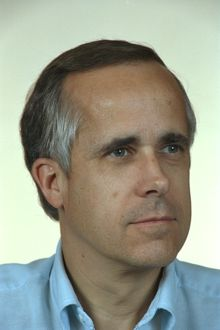
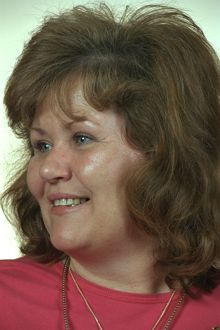
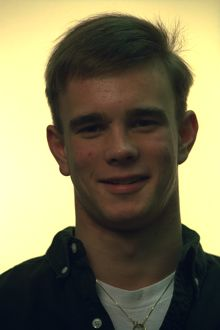
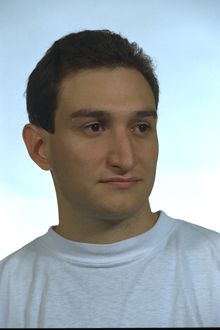
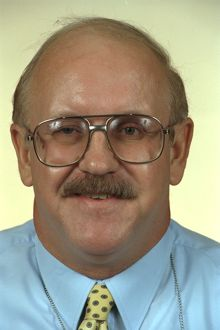
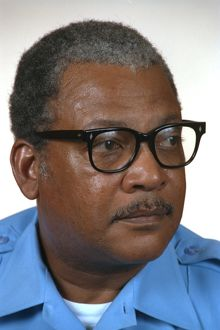
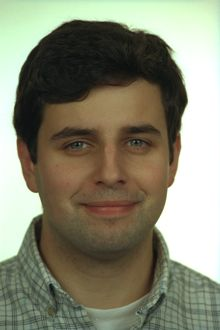
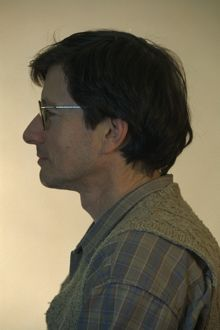
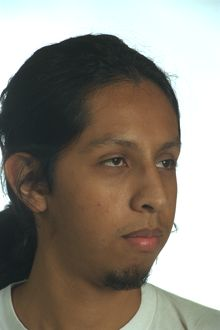
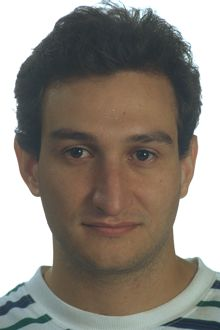

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Qwen3-8B,The passport-style face photo shows a head slightly turned. The face is unobstructed with a neutral expression and the mouth closed.,21,0.43,94,28
00480_940519_hl.png,Qwen3-8B,"The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted.",29,0.54,96,36
00230_940128_fb.png,Qwen3-8B,The passport-style face photo shows a head facing the camera with an unobstructed face. Issues include a non-neutral expression and an open mouth.,23,0.46,96,31
00256_941031_qr.png,Qwen3-8B,The passport-style face photo shows a head slightly turned. The face is unobstructed with a neutral expression and the mouth closed.,21,0.42,94,28
00503_940519_fa_a.png,Qwen3-8B,"The face photo shows a person with the head facing the camera. Issues include a partly covered face, a non-neutral expression, and an open mouth.",25,0.46,99,31
00544_940519_hr_a.png,Qwen3-8B,"The passport-style face photo shows a head slightly turned. The face is partly covered, for example by glasses. The expression is neutral, and the mouth is closed. No problems were found.",31,0.58,97,39
00248_940128_fb.png,Qwen3-8B,The passport-style face photo shows a head facing the camera with an unobstructed face and a closed mouth. Issues include a non-neutral expression.,23,0.47,96,31
00143_931230_pl_a.png,Qwen3-8B,"The passport-style face photo shows a head strongly turned, not facing the camera. The subject has a non-neutral expression and their mouth is open. No good aspects were noted.",29,0.53,96,36
00157_940928_rd.png,Qwen3-8B,"The passport-style face photo shows a head that is strongly turned, not facing the camera. The subject has a neutral expression with the mouth closed.",25,0.45,93,30
00256_940928_fa.png,Qwen3-8B,The passport-style face photo shows a head facing the camera. The face is unobstructed with a neutral expression.,18,0.38,94,25

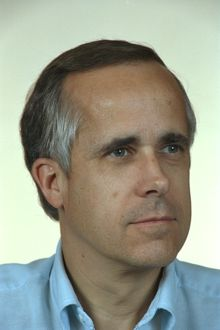
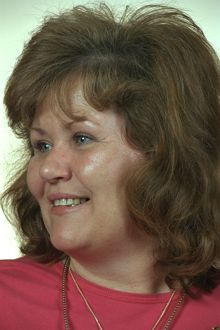
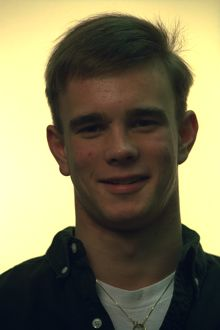
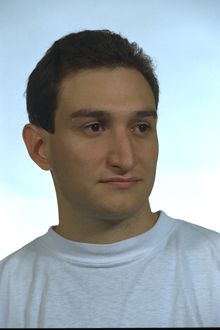
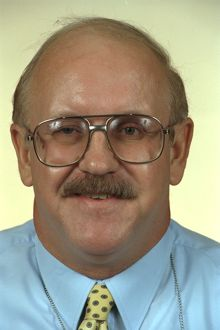
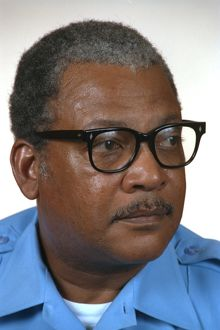
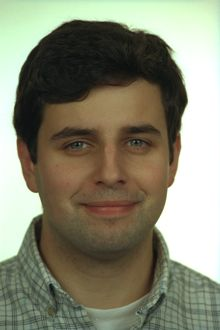
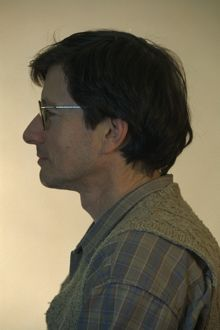
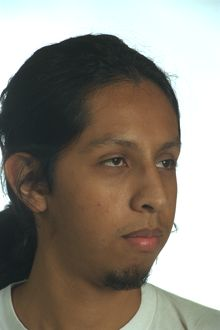
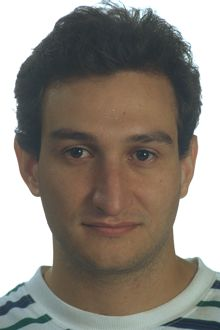

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Qwen3-4B,"The face is unobstructed, with a neutral expression and closed mouth. The head is slightly turned, which is noted as an issue.",22,0.28,94,30
00480_940519_hl.png,Qwen3-4B,"The photo shows a head strongly turned, non-neutral expression, and mouth open. No issues were found.",16,0.21,96,22
00230_940128_fb.png,Qwen3-4B,"The photo shows a head facing the camera with a clear, unobstructed face. No problems were found.",17,0.23,96,24
00256_941031_qr.png,Qwen3-4B,"The face is unobstructed, with a neutral expression and closed mouth. The head is slightly turned, which is noted as an issue.",22,0.28,94,30
00503_940519_fa_a.png,Qwen3-4B,The face is partly covered by glasses. The expression is not neutral and the mouth is open. No problems were found.,21,0.24,99,25
00544_940519_hr_a.png,Qwen3-4B,"The face is neutral with a closed mouth. Part of the face is covered, and the head is slightly turned. No problems were found.",24,0.27,97,29
00248_940128_fb.png,Qwen3-4B,"The photo shows a neutral expression, with the head facing the camera and the face fully visible. The mouth is closed, and no issues were found.",26,0.29,96,31
00143_931230_pl_a.png,Qwen3-4B,"The photo shows a head strongly turned, non-neutral expression, and mouth open. No issues were found.",16,0.21,96,22
00157_940928_rd.png,Qwen3-4B,"The photo shows a neutral expression with a closed mouth. The head is strongly turned, not facing the camera.",19,0.22,93,23
00256_940928_fa.png,Qwen3-4B,The face is centered and facing the camera. The face is fully visible with a neutral expression.,17,0.19,94,20

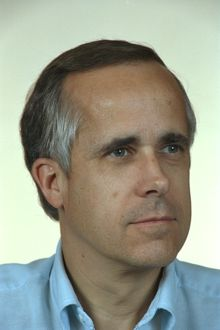
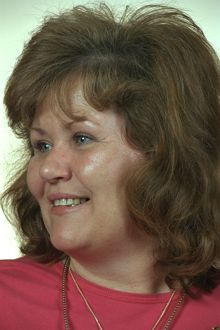
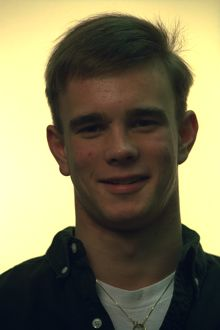
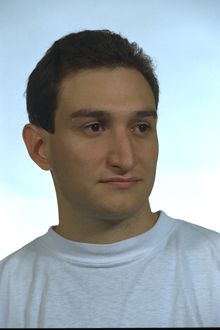
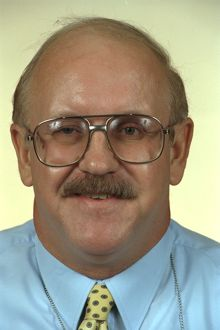
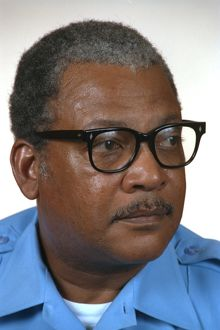
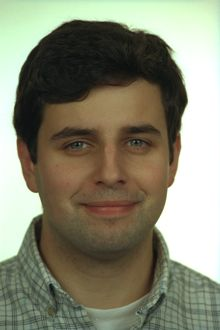
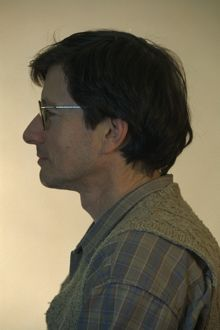
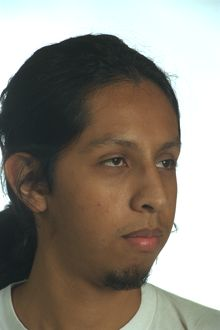
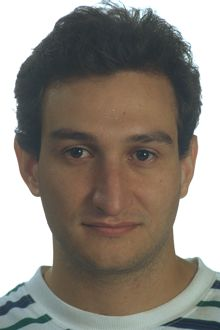

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Phi-4-mini,"The face photo shows a head slightly turned with an unobstructed face, neutral expression, and a closed mouth. No issues were found.",22,0.26,83,29
00480_940519_hl.png,Phi-4-mini,The face photo shows the head strongly turned away from the camera and a non-neutral expression with an open mouth. No good aspects were identified.,25,0.25,86,29
00230_940128_fb.png,Phi-4-mini,"The face photo shows the head facing the camera with an unobstructed view. However, there is a non-neutral expression with the mouth open. No other issues were found.",28,0.31,85,36
00256_941031_qr.png,Phi-4-mini,"The face photo shows a head slightly turned with an unobstructed face, neutral expression, and a closed mouth. No issues were found.",22,0.25,83,29
00503_940519_fa_a.png,Phi-4-mini,The face photo shows the head facing the camera but is partly covered by glasses. The expression is non-neutral with an open mouth. No issues were found.,27,0.28,89,32
00544_940519_hr_a.png,Phi-4-mini,"The face photo shows a neutral expression with a closed mouth. The head is slightly turned, and the face is partly covered by glasses. No problems were found.",28,0.28,87,33
00248_940128_fb.png,Phi-4-mini,"The face photo shows the head facing the camera with an unobstructed view of the face and a closed mouth. However, there is an issue with a non-neutral expression.",29,0.31,85,36
00143_931230_pl_a.png,Phi-4-mini,The face photo shows the head strongly turned away from the camera and a non-neutral expression with an open mouth. No good aspects were identified.,25,0.26,86,29
00157_940928_rd.png,Phi-4-mini,The face photo shows a neutral expression with a closed mouth. The head is strongly turned away from the camera. No problems were found.,24,0.25,83,28
00256_940928_fa.png,Phi-4-mini,The photo shows a head facing the camera with an unobstructed view of the face and a neutral expression. No issues were found.,23,0.25,83,28

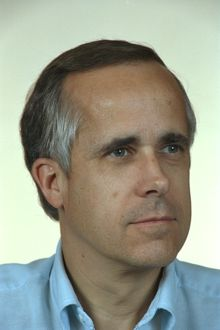
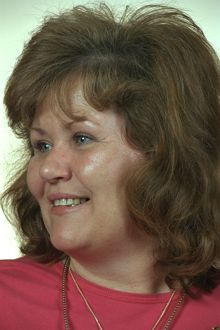
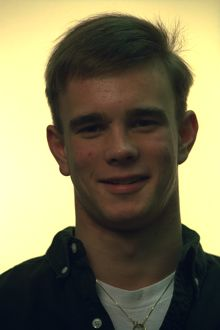
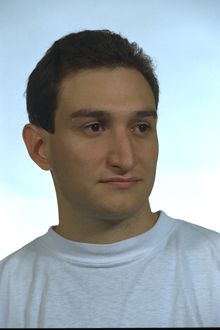
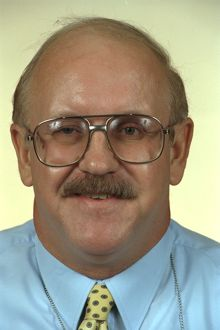
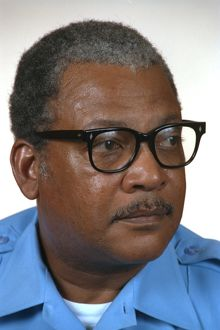
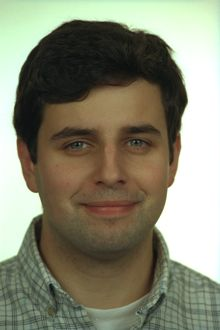
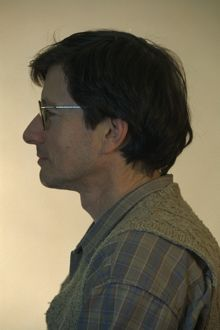
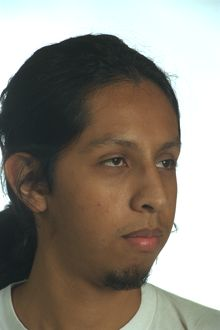
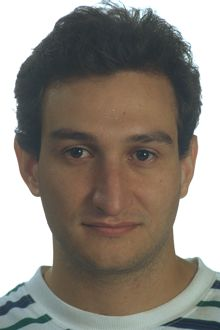

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Llama-3.1-8B,"The passport-style face photo shows a neutral expression with the mouth closed, and the face is unobstructed. The head is slightly turned, but no problems were found.",27,0.52,116,36
00480_940519_hl.png,Llama-3.1-8B,"The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found.",28,0.49,118,34
00230_940128_fb.png,Llama-3.1-8B,"The passport-style face photo shows a person with their head facing the camera and their face unobstructed. However, the photo has issues with a non-neutral expression and the mouth being open.",31,0.58,118,40
00256_941031_qr.png,Llama-3.1-8B,"The passport-style face photo shows a neutral expression with the mouth closed, and the face is unobstructed. The head is slightly turned, but no problems were found.",27,0.52,116,36
00503_940519_fa_a.png,Llama-3.1-8B,"The passport-style face photo shows a head facing the camera, but has some issues. The face is partly covered and the mouth is open, with no other problems found.",29,0.51,121,35
00544_940519_hr_a.png,Llama-3.1-8B,"The passport-style face photo shows a neutral expression with the mouth closed. The photo has some issues, including the head being slightly turned and the face being partly covered.",29,0.49,119,34
00248_940128_fb.png,Llama-3.1-8B,"The passport-style face photo shows a person with their head facing the camera and their face unobstructed. However, a non-neutral expression was found, with their mouth closed.",27,0.53,118,37
00143_931230_pl_a.png,Llama-3.1-8B,"The passport-style face photo shows a person with their head turned away from the camera, resulting in a non-neutral expression and an open mouth. No problems were found.",28,0.49,118,34
00157_940928_rd.png,Llama-3.1-8B,"The passport-style face photo shows a person with a neutral expression and mouth closed, but the head is not facing the camera directly. No problems were found.",27,0.46,115,32
00256_940928_fa.png,Llama-3.1-8B,"The passport-style face photo shows a person's head facing the camera, with their face fully visible and unobstructed. No problems were found, and the person has a neutral expression.",29,0.56,116,39

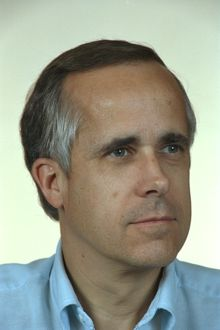
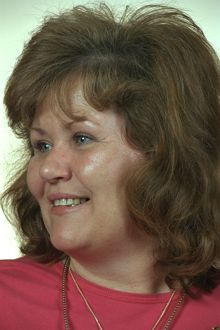
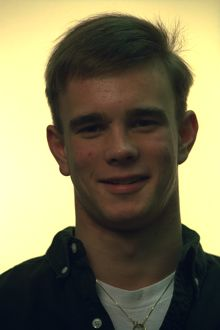
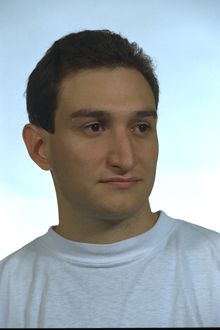
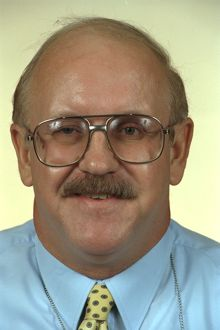
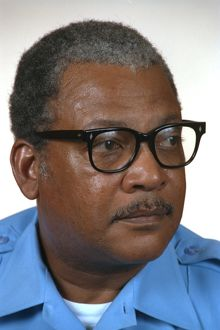
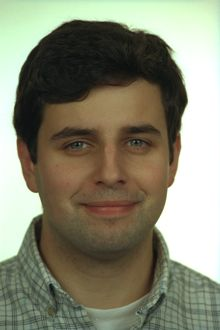
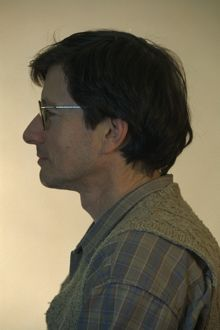
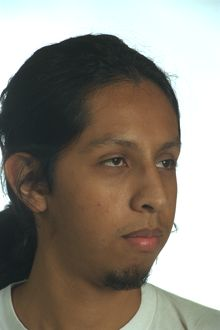
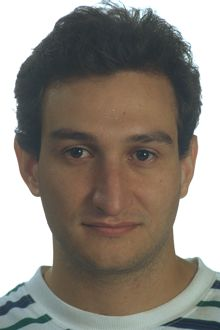

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,Gemma-3-1B,"The photograph depicts a face turned slightly to the left, with a neutral expression. The face is largely unobstructed, showcasing a closed mouth.",23,0.15,91,28
00480_940519_hl.png,Gemma-3-1B,"The image features a person with a significantly turned head, presenting a lack of direct engagement with the camera. The expression is not neutral, and the mouth is open, creating a slightly inquisitive pose.",34,0.21,97,40
00230_940128_fb.png,Gemma-3-1B,"Here’s a description: The image features a head facing forward, with a slightly open mouth. The face is clearly defined and appears to be unposed.",25,0.18,94,34
00256_941031_qr.png,Gemma-3-1B,"The photograph depicts a face turned slightly to the left, with a neutral expression. The face is largely unobstructed, showcasing a closed mouth.",23,0.15,91,28
00503_940519_fa_a.png,Gemma-3-1B,"Here’s a description: The image features a face partially obscured by glasses, with a gentle curve to the jawline. The mouth is open, and the head is facing directly towards the camera.",32,0.22,100,42
00544_940519_hr_a.png,Gemma-3-1B,"Here’s a description: A face is turned slightly to the left, with a portion of the face obscured by glasses. The expression is neutral, with the mouth closed, creating a calm and composed appearance.",34,0.23,97,44
00248_940128_fb.png,Gemma-3-1B,"Here’s a description: The image features a head facing the camera, with a closed mouth and a neutral expression. The face is clearly unobstructed, presenting a simple and straightforward portrait.",30,0.2,94,39
00143_931230_pl_a.png,Gemma-3-1B,"The image features a person with a significantly turned head, presenting a lack of direct engagement with the camera. The expression is not neutral, and the mouth is open, creating a slightly inquisitive pose.",34,0.2,97,40
00157_940928_rd.png,Gemma-3-1B,"The image features a head turned slightly to the side, presenting a neutral expression. The mouth is closed, creating a calm and composed appearance.",24,0.16,93,29
00256_940928_fa.png,Gemma-3-1B,"Here’s a description: The image features a person with a centered, forward-facing gaze. The face is composed of a smooth, unblemished surface, presenting a calm and neutral expression.",28,0.23,91,42

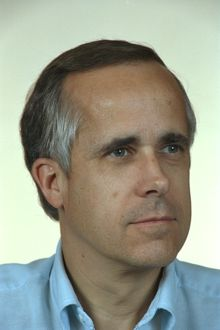
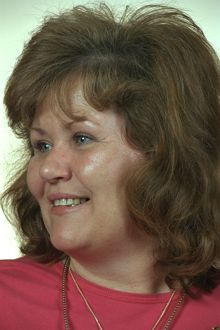
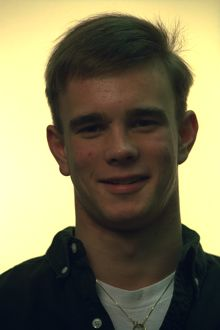
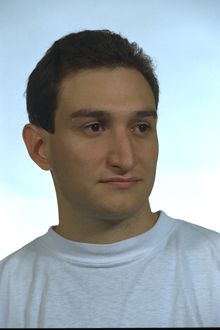
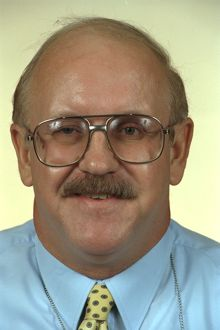
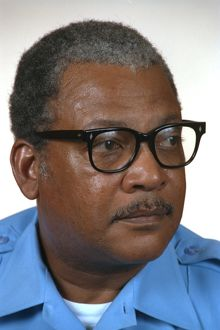
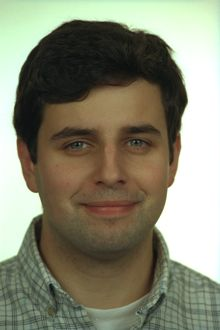
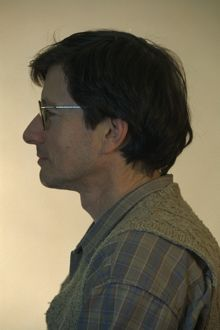
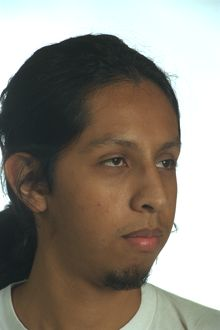
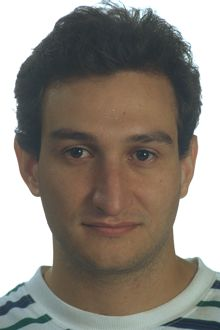

immagine,modello,risposta,num_parole,tempo_s,prompt_tokens,completion_tokens
00519_940519_qr.png,LFM2-1.2B,"The photo features a face with a slight tilt of the head, a neutral expression, and a closed mouth, all unobstructed.",21,0.1,93,29
00480_940519_hl.png,LFM2-1.2B,"The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.",21,0.1,95,27
00230_940128_fb.png,LFM2-1.2B,"The face photo features a neutral expression with the mouth slightly open, the subject's head turned towards the camera, and the mouth unobstructed.",23,0.11,95,31
00256_941031_qr.png,LFM2-1.2B,"The photo features a face with a slight tilt of the head, a neutral expression, and a closed mouth, all unobstructed.",21,0.1,93,29
00503_940519_fa_a.png,LFM2-1.2B,"The face shows a partial coverage, like glasses, with a non-neutral expression and mouth slightly open, facing the camera directly.",20,0.09,98,27
00544_940519_hr_a.png,LFM2-1.2B,"The face photo shows a neutral expression with a slightly turned head and a partially covered mouth, likely due to glasses. The overall appearance is clean and unobtrusive.",28,0.12,96,35
00248_940128_fb.png,LFM2-1.2B,"The face photo features a neutral expression with the subject's head turned towards the camera, a clear, unobstructed face, and a mouth closed. No issues detected.",26,0.12,95,36
00143_931230_pl_a.png,LFM2-1.2B,"The face shows a strong head tilt, a non-neutral expression, and an open mouth. The overall appearance lacks any positive attributes.",21,0.1,95,27
00157_940928_rd.png,LFM2-1.2B,"The face photo features a head turned sharply, eyes slightly open, mouth closed, with a neutral expression. The subject's gaze is directed away from the camera.",26,0.12,92,33
00256_940928_fa.png,LFM2-1.2B,"The photo features a person with a passport-style face, head turned directly at the camera, with an unobstructed face and a neutral expression. The overall composition is clear and professional.",30,0.13,93,39

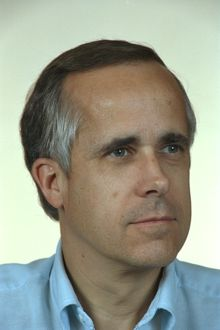
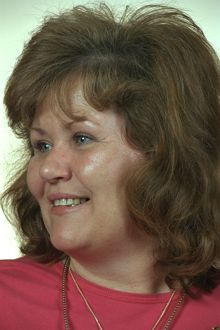
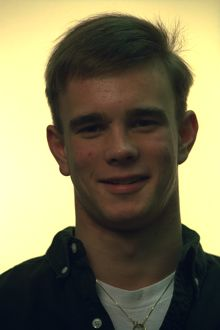
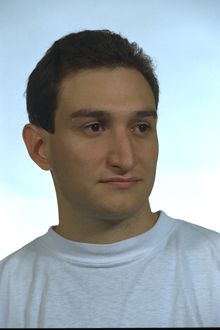
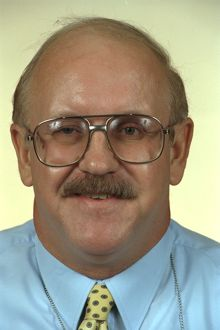
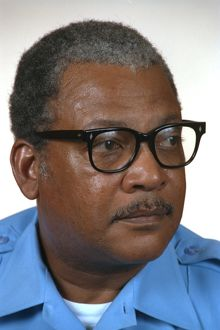
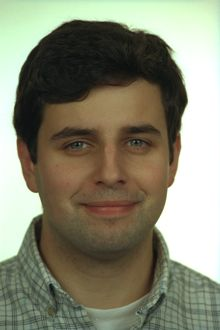
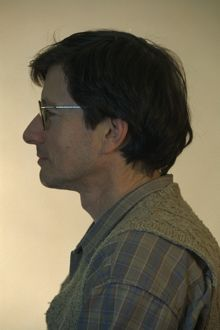
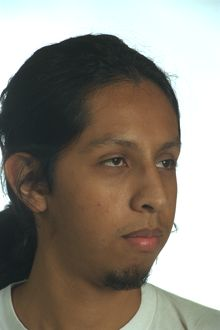
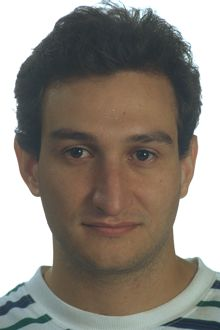

In [40]:
for m in df.select('modello').unique().iter_rows():
    x, = m
    mostra_tabella(df.filter(pl.col('modello') == x), "~/prove/feret_all/images", n=10)    